In [ ]:
print("CodeNova Data Science Internship")
print("My first Sales Data Analysis project")

CodeNova Data Science Internship
My first Sales Data Analysis project


In [ ]:

print("Welcome to CodeNova Internship!")
print("Project: Sales Data Analysis")
print("Let's start learning Data Science!")


Welcome to CodeNova Internship!
Project: Sales Data Analysis
Let's start learning Data Science!


In [ ]:

import pandas as pd

data = {
    "Product": ["Laptop", "Phone", "Tablet", "Laptop", "Phone", "Tablet"],
    "Category": ["Electronics", "Electronics", "Electronics",
                 "Electronics", "Electronics", "Electronics"],
    "Quantity": [2, 5, 3, 1, 4, 2],
    "Price": [50000, 15000, 20000, 50000, 15000, 20000]
}

df = pd.DataFrame(data)
df["Sales"] = df["Quantity"] * df["Price"]

print(df)


  Product     Category  Quantity  Price   Sales
0  Laptop  Electronics         2  50000  100000
1   Phone  Electronics         5  15000   75000
2  Tablet  Electronics         3  20000   60000
3  Laptop  Electronics         1  50000   50000
4   Phone  Electronics         4  15000   60000
5  Tablet  Electronics         2  20000   40000


In [ ]:

# Calculate total sales
total_sales = df["Sales"].sum()

print("Total Sales = Rs.", total_sales)


Total Sales = Rs. 385000


In [ ]:

product_sales = df.groupby("Product")["Sales"].sum()

print("Product-wise Sales:")
print(product_sales)


Product-wise Sales:
Product
Laptop    150000
Phone     135000
Tablet    100000
Name: Sales, dtype: int64


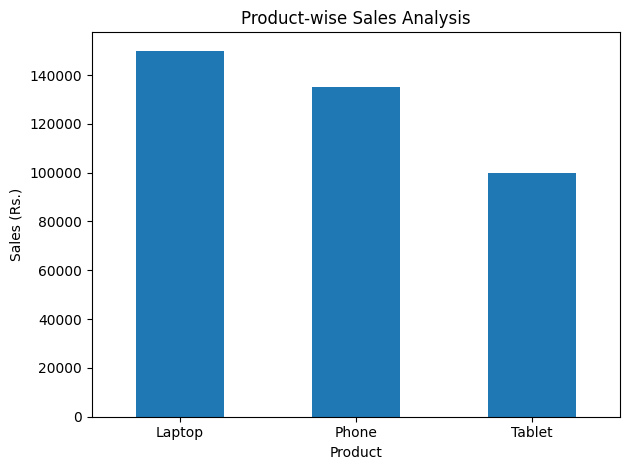

In [ ]:

import matplotlib.pyplot as plt

product_sales.plot(kind="bar")

plt.title("Product-wise Sales Analysis")
plt.xlabel("Product")
plt.ylabel("Sales (Rs.)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

# Sample cost per unit (practice values)
unit_cost = {
    "Laptop": 40000,
    "Phone": 10000,
    "Tablet": 15000
}

df["Unit_Cost"] = df["Product"].map(unit_cost)
df["Total_Cost"] = df["Quantity"] * df["Unit_Cost"]
df["Profit"] = df["Sales"] - df["Total_Cost"]

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = (total_profit / total_sales) * 100

print("Total Revenue: Rs.", total_sales)
print("Total Profit: Rs.", total_profit)
print("Profit Margin: {:.2f}%".format(profit_margin))

display(df)


Total Revenue: Rs. 385000
Total Profit: Rs. 100000
Profit Margin: 25.97%


,Product,Category,Quantity,Price,Sales,Unit_Cost,Total_Cost,Profit
0,Laptop,Electronics,2,50000,100000,40000,80000,20000
1,Phone,Electronics,5,15000,75000,10000,50000,25000
2,Tablet,Electronics,3,20000,60000,15000,45000,15000
3,Laptop,Electronics,1,50000,50000,40000,40000,10000
4,Phone,Electronics,4,15000,60000,10000,40000,20000
5,Tablet,Electronics,2,20000,40000,15000,30000,10000


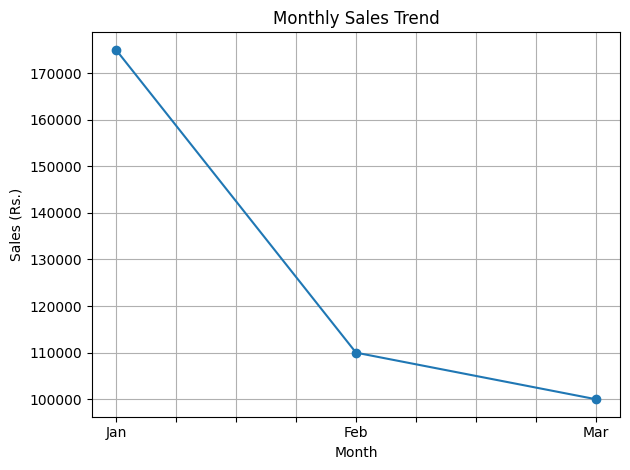

,Sales
Month,
Jan,175000
Feb,110000
Mar,100000


In [ ]:

df["Date"] = pd.to_datetime([
    "2026-01-05",
    "2026-01-12",
    "2026-02-03",
    "2026-02-18",
    "2026-03-10",
    "2026-03-22"
])

df["Month"] = df["Date"].dt.strftime("%b")

monthly_sales = df.groupby("Month")["Sales"].sum()

monthly_sales = monthly_sales.reindex(["Jan", "Feb", "Mar"])

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (Rs.)")
plt.grid(True)
plt.tight_layout()
plt.show()

display(monthly_sales)


,Total_Quantity,Revenue,Profit,Profit_Margin_%
Product,,,,
Laptop,3,150000,30000,20.00
Phone,9,135000,45000,33.33
Tablet,5,100000,25000,25.00


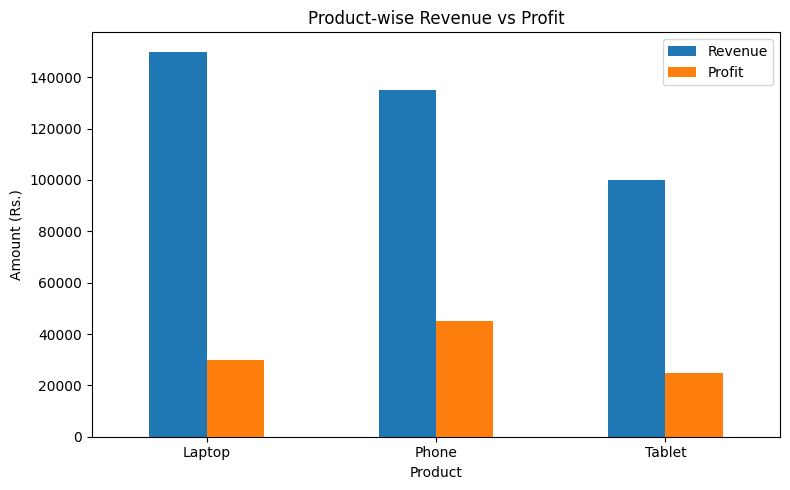

In [ ]:

# Product-wise revenue and profit analysis

product_summary = df.groupby("Product").agg(
    Total_Quantity=("Quantity", "sum"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum")
)

product_summary["Profit_Margin_%"] = (
    product_summary["Profit"] / product_summary["Revenue"] * 100
).round(2)

display(product_summary)

# Compare revenue and profit
product_summary[["Revenue", "Profit"]].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Product-wise Revenue vs Profit")
plt.xlabel("Product")
plt.ylabel("Amount (Rs.)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

best_revenue_product = product_summary["Revenue"].idxmax()
best_profit_product = product_summary["Profit"].idxmax()

print("BUSINESS INSIGHTS")
print("-----------------")
print("Highest revenue product:", best_revenue_product)
print("Highest profit product:", best_profit_product)
print("Total revenue: Rs.", total_sales)
print("Total profit: Rs.", total_profit)
print("Overall profit margin: {:.2f}%".format(profit_margin))

print("\nRECOMMENDATIONS")
print("1. Monitor sales and profit for each product.")
print("2. Promote products that generate strong profits.")
print("3. Review product costs and pricing regularly.")


BUSINESS INSIGHTS
-----------------
Highest revenue product: Laptop
Highest profit product: Phone
Total revenue: Rs. 385000
Total profit: Rs. 100000
Overall profit margin: 25.97%

RECOMMENDATIONS
1. Monitor sales and profit for each product.
2. Promote products that generate strong profits.
3. Review product costs and pricing regularly.


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving online+retail.zip to online+retail.zip


In [ ]:
print(uploaded.keys())
file_name = list(uploaded.keys())[0]
print(file_name)

dict_keys(['online+retail.zip'])
online+retail.zip


In [ ]:
!pip install openpyxl

In [ ]:

import zipfile
import os

zip_file = "online+retail.zip"

with zipfile.ZipFile(zip_file, "r") as z:
    print(z.namelist())


['Online Retail.xlsx']


In [ ]:

import zipfile
import os
import pandas as pd

with zipfile.ZipFile("online+retail.zip", "r") as z:
    z.extractall("retail_data")

for root, dirs, files in os.walk("retail_data"):
    for file in files:
        print(file)


Online Retail.xlsx


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = os.path.join("retail_data", "Online Retail.xlsx")

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

# Check dataset information
print("\nDataset Information:")
df.info()


Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total Duplicate Rows:
5268

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:

# Remove rows with missing product descriptions or prices
sales_df = df.dropna(subset=["Description", "Quantity", "UnitPrice"]).copy()

# Remove cancelled transactions
sales_df = sales_df[
    ~sales_df["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities and prices
sales_df = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

# Calculate revenue for each item
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Calculate key business metrics
total_revenue = sales_df["Revenue"].sum()
total_quantity = sales_df["Quantity"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
average_order_value = total_revenue / total_orders

print("Total Revenue: £{:.2f}".format(total_revenue))
print("Total Quantity Sold:", total_quantity)
print("Total Orders:", total_orders)
print("Average Order Value: £{:.2f}".format(average_order_value))


Total Revenue: £10666684.54
Total Quantity Sold: 5588376
Total Orders: 19960
Average Order Value: £534.40


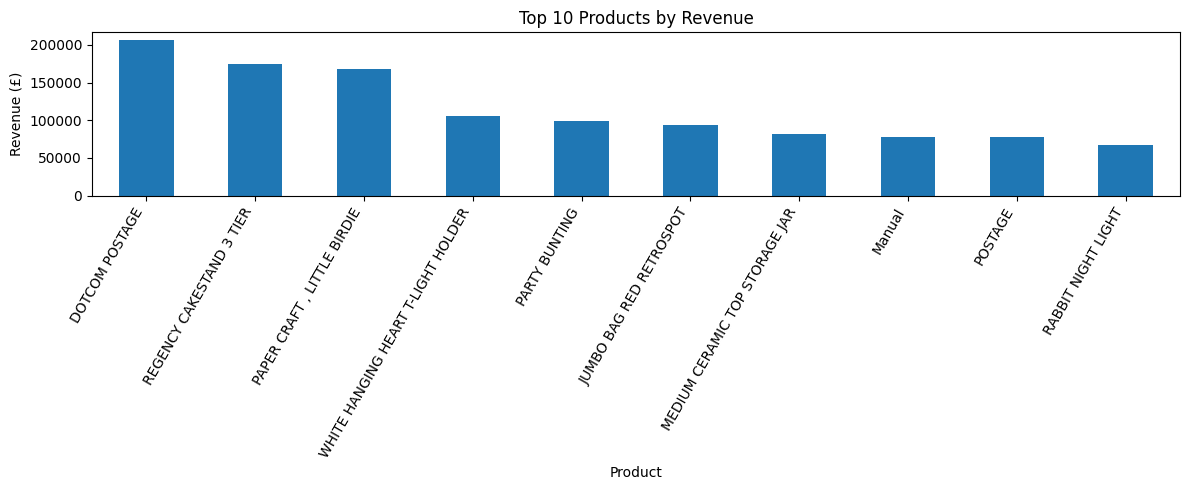

In [ ]:

top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.plot(kind="bar", figsize=(12, 5))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


Monthly Sales Revenue:
Month
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64


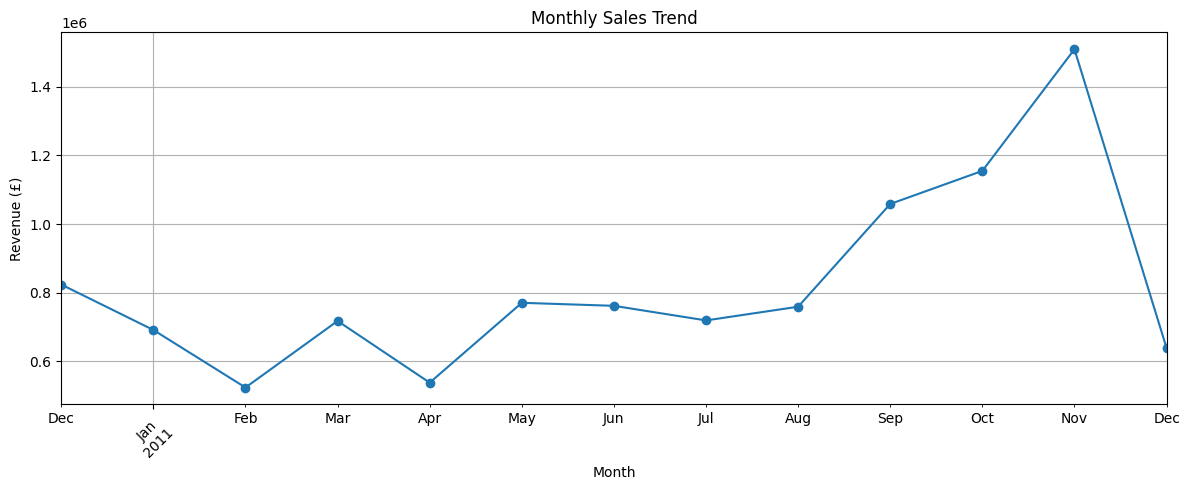

In [ ]:

# Convert InvoiceDate into date format
sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"]
)

# Extract month and year
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = sales_df.groupby("Month")["Revenue"].sum()

# Display monthly sales
print("Monthly Sales Revenue:")
print(monthly_sales)

# Create line chart
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Top 10 Countries by Revenue:
Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64


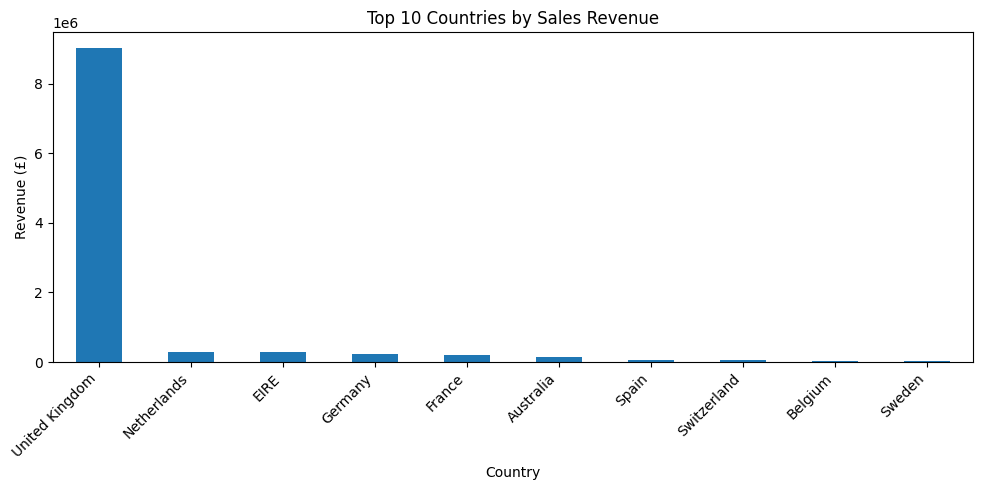

In [ ]:

# Calculate sales for each country
country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 countries
top_countries = country_sales.head(10)

print("Top 10 Countries by Revenue:")
print(top_countries)

# Create bar chart
top_countries.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Top 10 Products by Quantity Sold:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


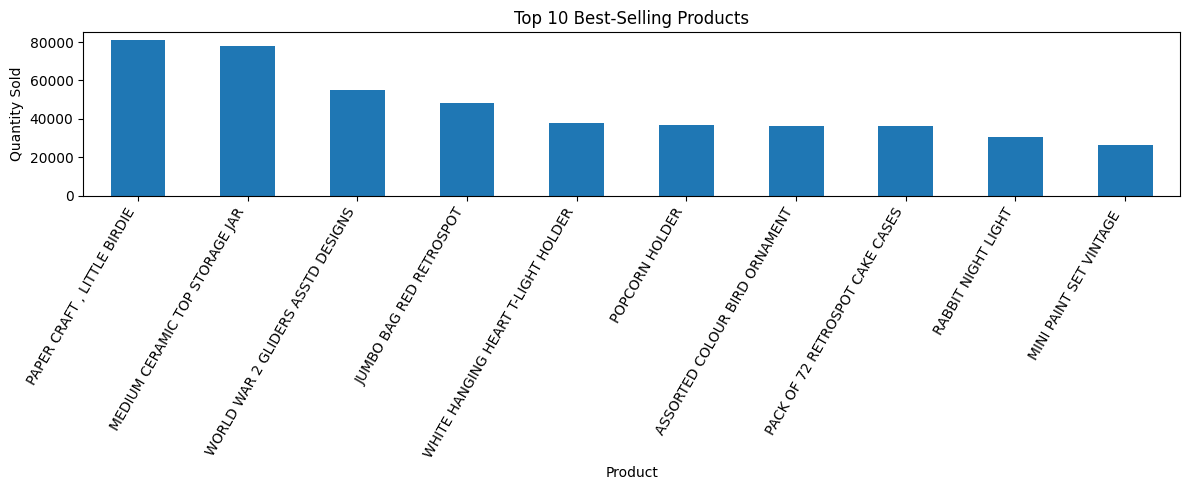

In [ ]:

# Top 10 products by quantity sold
top_quantity = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
print(top_quantity)

top_quantity.plot(kind="bar", figsize=(12, 5))

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

# Find the best month by revenue
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

# Find the top country
best_country = country_sales.idxmax()
best_country_revenue = country_sales.max()

# Find the top product by revenue
best_product = sales_df.groupby("Description")["Revenue"].sum().idxmax()
best_product_revenue = sales_df.groupby("Description")["Revenue"].sum().max()

print("BUSINESS INSIGHTS")
print("---------------------------")

print("Best Sales Month:", best_month)
print("Revenue in Best Month: £{:.2f}".format(best_month_revenue))

print("\nTop Country:", best_country)
print("Country Revenue: £{:.2f}".format(best_country_revenue))

print("\nTop Product:", best_product)
print("Product Revenue: £{:.2f}".format(best_product_revenue))


BUSINESS INSIGHTS
---------------------------
Best Sales Month: 2011-11
Revenue in Best Month: £1509496.33

Top Country: United Kingdom
Country Revenue: £9025222.08

Top Product: DOTCOM POSTAGE
Product Revenue: £206248.77


In [ ]:

# Keep the original dataset safe
raw_df = df.copy()

# Check the original dataset
print("BEFORE CLEANING")
print("Total rows:", len(raw_df))
print("Total columns:", len(raw_df.columns))
print("Missing values:", raw_df.isnull().sum().sum())
print("Duplicate rows:", raw_df.duplicated().sum())

# Check data types
print("\nColumn Data Types:")
print(raw_df.dtypes)


BEFORE CLEANING
Total rows: 541909
Total columns: 8
Missing values: 136534
Duplicate rows: 5268

Column Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [ ]:

# Create a separate copy for cleaning
clean_df = raw_df.copy()

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Remove rows where important fields are missing
clean_df = clean_df.dropna(
    subset=["InvoiceNo", "StockCode", "Quantity",
            "InvoiceDate", "UnitPrice"]
)

# Remove invalid quantities and prices
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

print("DATA CLEANING RESULTS")
print("---------------------")
print("Rows before cleaning:", len(raw_df))
print("Rows after cleaning:", len(clean_df))
print("Rows removed:", len(raw_df) - len(clean_df))
print("Missing values remaining:", clean_df.isnull().sum().sum())
print("Duplicate rows remaining:", clean_df.duplicated().sum())


DATA CLEANING RESULTS
---------------------
Rows before cleaning: 541909
Rows after cleaning: 524878
Rows removed: 17031
Missing values remaining: 132186
Duplicate rows remaining: 0


In [ ]:

# Compare original and cleaned datasets

comparison = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Missing Values",
        "Duplicate Rows"
    ],
    "Before Cleaning": [
        len(raw_df),
        raw_df.isnull().sum().sum(),
        raw_df.duplicated().sum()
    ],
    "After Cleaning": [
        len(clean_df),
        clean_df.isnull().sum().sum(),
        clean_df.duplicated().sum()
    ]
})

display(comparison)


,Metric,Before Cleaning,After Cleaning
0,Total Rows,541909,524878
1,Missing Values,136534,132186
2,Duplicate Rows,5268,0


In [ ]:

report = f"""
DATA CLEANING REPORT
====================

Dataset: Online Retail

1. Original number of rows: {len(raw_df)}

2. Rows after cleaning: {len(clean_df)}

3. Rows removed: {len(raw_df) - len(clean_df)}

4. Missing values before cleaning:
{raw_df.isnull().sum().to_string()}

5. Missing values after cleaning:
{clean_df.isnull().sum().to_string()}

6. Duplicate rows before cleaning:
{raw_df.duplicated().sum()}

7. Duplicate rows after cleaning:
{clean_df.duplicated().sum()}

Cleaning steps:
- Removed duplicate records.
- Removed rows missing important transaction fields.
- Removed records with non-positive quantities or prices.
"""

with open("Data_Cleaning_Report.txt", "w") as file:
    file.write(report)

print(report)
print("\nReport saved successfully!")



DATA CLEANING REPORT

Dataset: Online Retail

1. Original number of rows: 541909

2. Rows after cleaning: 524878

3. Rows removed: 17031

4. Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0

5. Missing values after cleaning:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0

6. Duplicate rows before cleaning:
5268

7. Duplicate rows after cleaning:
0

Cleaning steps:
- Removed duplicate records.
- Removed rows missing important transaction fields.
- Removed records with non-positive quantities or prices.


Report saved successfully!


In [ ]:

# Save the cleaned dataset
clean_df.to_csv("Cleaned_Online_Retail.csv", index=False)

print("Cleaned dataset saved successfully!")

# Download the file
from google.colab import files
files.download("Cleaned_Online_Retail.csv")


Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("Data_Cleaning_Report.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(page_title="Sales Dashboard", layout="wide")

st.title("Online Retail Sales Dashboard")
st.write("Interactive analysis of online retail sales")

@st.cache_data
def load_data():
    data = pd.read_csv("Cleaned_Online_Retail.csv")
    data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
    data["Revenue"] = data["Quantity"] * data["UnitPrice"]
    return data

df = load_data()

# Country filter
countries = ["All"] + sorted(df["Country"].dropna().unique().tolist())
selected_country = st.selectbox("Select Country", countries)

if selected_country != "All":
    data = df[df["Country"] == selected_country].copy()
else:
    data = df.copy()

# Summary metrics
total_revenue = data["Revenue"].sum()
total_orders = data["InvoiceNo"].nunique()
total_quantity = data["Quantity"].sum()

col1, col2, col3 = st.columns(3)

col1.metric("Total Revenue", f"£{total_revenue:,.2f}")
col2.metric("Total Orders", f"{total_orders:,}")
col3.metric("Quantity Sold", f"{total_quantity:,}")

# Monthly sales chart
st.subheader("Monthly Sales Trend")

data["Month"] = data["InvoiceDate"].dt.to_period("M").astype(str)
monthly_sales = data.groupby("Month")["Revenue"].sum()

st.line_chart(monthly_sales)

# Top products chart
st.subheader("Top 10 Products by Revenue")

top_products = (
    data.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

st.bar_chart(top_products)

# Country summary
st.subheader("Country-wise Sales")

country_summary = (
    data.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

st.bar_chart(country_summary)

st.subheader("Sales Data Preview")
st.dataframe(data.head(100))


Writing app.py


In [ ]:

!pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 97.2 MB/s eta 0:00:00


In [ ]:

import os

print("app.py exists:", os.path.exists("app.py"))
print("Dataset exists:", os.path.exists("Cleaned_Online_Retail.csv"))


app.py exists: True
Dataset exists: True


In [ ]:

!streamlit run app.py &>/content/streamlit.log &


In [ ]:

!pip install -q pyngrok

!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

import os

print("app.py:", os.path.exists("app.py"))
print("Cleaned dataset:", os.path.exists("Cleaned_Online_Retail.csv"))
print("\nServer log:")
print(open("/content/streamlit.log").read()[-1500:])


app.py: True
Cleaned dataset: True

Server log:



In [ ]:

import time
import requests

time.sleep(5)

try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    )
    print("Server status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Server not responding:", e)

print("\nServer log:")
with open("/content/streamlit.log", "r") as f:
    print(f.read()[-3000:] or "Log is still empty")


Server status: 200
Response: ok

Server log:


2026-10-13 15:31:38.981 Port 8501 is not available



In [ ]:

from google.colab import output

output.serve_kernel_port_as_window(8501)


Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:

from google.colab import output

output.serve_kernel_port_as_iframe(8501)


<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

# Use the cleaned retail dataset
customer_df = clean_df.copy()

# Calculate total spending for each customer
customer_df["Revenue"] = (
    customer_df["Quantity"] * customer_df["UnitPrice"]
)

customer_summary = (
    customer_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        TotalOrders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalSpending=("Revenue", "sum")
    )
    .reset_index()
)

print("Customer summary:")
display(customer_summary.head())

print("\nTotal customers:", len(customer_summary))


Customer summary:


,CustomerID,TotalOrders,TotalQuantity,TotalSpending
0,12346.0,1,74215,77183.60
1,12347.0,7,2458,4310.00
2,12348.0,4,2341,1797.24
3,12349.0,1,631,1757.55
4,12350.0,1,197,334.40



Total customers: 4338


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Customer details copy
seg_df = customer_summary.copy()

# Important columns
features = ["TotalOrders", "TotalQuantity", "TotalSpending"]

# Remove zero or negative values
seg_df = seg_df[(seg_df[features] > 0).all(axis=1)].copy()

# Scale the data
X = np.log1p(seg_df[features])
X_scaled = StandardScaler().fit_transform(X)

# Divide customers into 3 groups
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
seg_df["Segment"] = kmeans.fit_predict(X_scaled)

print("Customer Segmentation Completed!")
print("Total customers:", len(seg_df))

display(seg_df.head())

print("Segment Summary:")
display(
    seg_df.groupby("Segment")[features]
    .mean()
    .round(2)
)


Customer Segmentation Completed!
Total customers: 4338


,CustomerID,TotalOrders,TotalQuantity,TotalSpending,Segment
0,12346.0,1,74215,77183.60,1
1,12347.0,7,2458,4310.00,1
2,12348.0,4,2341,1797.24,2
3,12349.0,1,631,1757.55,2
4,12350.0,1,197,334.40,0


Segment Summary:


,TotalOrders,TotalQuantity,TotalSpending
Segment,,,
0,1.29,145.67,265.40
1,12.67,4402.48,7625.07
2,3.17,671.43,1130.04


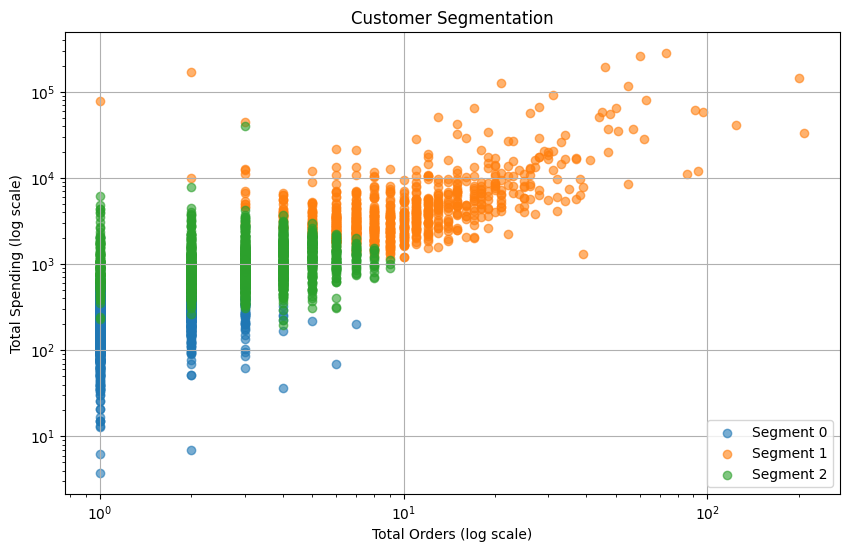

In [ ]:

plt.figure(figsize=(10, 6))

for segment in sorted(seg_df["Segment"].unique()):
    group = seg_df[seg_df["Segment"] == segment]
    plt.scatter(
        group["TotalOrders"],
        group["TotalSpending"],
        label=f"Segment {segment}",
        alpha=0.6
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Total Orders (log scale)")
plt.ylabel("Total Spending (log scale)")
plt.title("Customer Segmentation")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

seg_df.to_csv("Customer_Segmentation.csv", index=False)

segment_summary = (
    seg_df.groupby("Segment")[features]
    .mean()
    .round(2)
)

segment_summary.to_csv("Customer_Segment_Summary.csv")

print("Both files saved successfully!")


Both files saved successfully!


In [ ]:

# Create customer segmentation report

segment_summary = (
    seg_df.groupby("Segment")
    .agg(
        Number_of_Customers=("CustomerID", "count"),
        Average_Orders=("TotalOrders", "mean"),
        Average_Quantity=("TotalQuantity", "mean"),
        Average_Spending=("TotalSpending", "mean")
    )
    .round(2)
    .reset_index()
)

display(segment_summary)

# Save summary as CSV
segment_summary.to_csv(
    "Customer_Segment_Summary.csv",
    index=False
)

# Save customer-level segmentation
seg_df.to_csv(
    "Customer_Segmentation.csv",
    index=False
)

# Create text report
with open("Customer_Segmentation_Report.txt", "w") as file:
    file.write("CUSTOMER SEGMENTATION REPORT\n")
    file.write("============================\n\n")
    file.write(
        "Customers were grouped into 3 segments using the "
        "K-Means clustering algorithm.\n\n"
    )
    file.write(segment_summary.to_string(index=False))
    file.write(
        "\n\nFeatures used: Total Orders, Total Quantity, "
        "and Total Spending.\n"
    )
    file.write(
        "\nPurpose: To understand customer purchasing behaviour "
        "and support targeted marketing decisions.\n"
    )

print("Report and CSV files created successfully!")


,Segment,Number_of_Customers,Average_Orders,Average_Quantity,Average_Spending
0,0,1716,1.29,145.67,265.40
1,1,842,12.67,4402.48,7625.07
2,2,1780,3.17,671.43,1130.04


Report and CSV files created successfully!


In [ ]:

from google.colab import files

files.download("Customer_Segmentation.csv")
files.download("Customer_Segment_Summary.csv")
files.download("Customer_Segmentation_Report.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(page_title="Sales Dashboard", layout="wide")

st.title("Online Retail Sales Dashboard")
st.write("Interactive analysis of online retail sales")

@st.cache_data
def load_data():
    data = pd.read_csv("Cleaned_Online_Retail.csv")
    data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
    data["Revenue"] = data["Quantity"] * data["UnitPrice"]
    return data

df = load_data()

countries = ["All"] + sorted(df["Country"].dropna().unique().tolist())
selected_country = st.selectbox("Select Country", countries)

data = df if selected_country == "All" else df[df["Country"] == selected_country].copy()

col1, col2, col3 = st.columns(3)

col1.metric("Total Revenue", f"£{data['Revenue'].sum():,.2f}")
col2.metric("Total Orders", f"{data['InvoiceNo'].nunique():,}")
col3.metric("Quantity Sold", f"{data['Quantity'].sum():,}")

data = data.copy()
data["Month"] = data["InvoiceDate"].dt.to_period("M").astype(str)

st.subheader("Monthly Sales Trend")
st.line_chart(data.groupby("Month")["Revenue"].sum())

st.subheader("Top 10 Products by Revenue")
st.bar_chart(
    data.groupby("Description")["Revenue"]
    .sum().sort_values(ascending=False).head(10)
)

st.subheader("Country-wise Sales")
st.bar_chart(
    data.groupby("Country")["Revenue"]
    .sum().sort_values(ascending=False).head(10)
)

st.subheader("Sales Data Preview")
st.dataframe(data.head(100))


Overwriting app.py


In [ ]:

from google.colab import files
files.download("app.py")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import zipfile
import os

csv_file = "Cleaned_Online_Retail.csv"
zip_file = "Cleaned_Online_Retail.zip"

with zipfile.ZipFile(
    zip_file, "w", zipfile.ZIP_DEFLATED
) as z:
    z.write(csv_file, arcname=csv_file)

size_mb = os.path.getsize(zip_file) / (1024 * 1024)

print(f"ZIP file size: {size_mb:.2f} MB")


ZIP file size: 7.18 MB


In [ ]:

from google.colab import files
files.download("Cleaned_Online_Retail.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

data = pd.read_csv(
    "Cleaned_Online_Retail.csv",
    low_memory=False
)

print("Dataset loaded successfully!")
print("Rows and columns:", data.shape)


Dataset loaded successfully!
Rows and columns: (524878, 8)


In [ ]:

import zipfile
import os

with zipfile.ZipFile(
    "Cleaned_Online_Retail.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    z.write(
        "Cleaned_Online_Retail.csv",
        arcname="Cleaned_Online_Retail.csv"
    )

size_mb = os.path.getsize("Cleaned_Online_Retail.zip") / (1024 * 1024)

print(f"ZIP file size: {size_mb:.2f} MB")


ZIP file size: 7.18 MB


In [ ]:

import os

zip_path = "Cleaned_Online_Retail.zip"

if os.path.exists(zip_path):
    size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"ZIP file size: {size_mb:.2f} MB")

    if size_mb < 25:
        print("GitHub upload-ku size OK!")
    else:
        print("GitHub limit exceed aagudhu.")
else:
    print("ZIP file innum create aagala. Previous ZIP code run pannu.")


ZIP file size: 7.18 MB
GitHub upload-ku size OK!


In [ ]:

# Create a small sample dataset for GitHub
sample_df = clean_df.head(500).copy()

sample_df.to_csv("Online_Retail_Sample.csv", index=False)

from google.colab import files
files.download("Online_Retail_Sample.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

print("Total rows:", len(df))
print("Available dates:")
print(df["InvoiceDate"].min())
print(df["InvoiceDate"].max())
print("\nMonths available:")
print(
    pd.to_datetime(df["InvoiceDate"])
    .dt.strftime("%Y-%m")
    .dropna()
    .unique()
)


Total rows: 541909
Available dates:
2010-12-01 08:26:00
2011-12-09 12:50:00

Months available:
['2010-12' '2011-01' '2011-02' '2011-03' '2011-04' '2011-05' '2011-06'
 '2011-07' '2011-08' '2011-09' '2011-10' '2011-11' '2011-12']


In [ ]:

# Create full cleaned sales dataset
sales_df.to_csv("Online_Retail_Full.csv", index=False)

import os
size_mb = os.path.getsize("Online_Retail_Full.csv") / (1024 * 1024)

print(f"Full dataset created: {size_mb:.2f} MB")


Full dataset created: 52.53 MB


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Online_Retail_Sample.csv to Online_Retail_Sample.csv


In [4]:
import pandas as pd

df = pd.read_csv("Online_Retail_Sample.csv")

print("Total rows:", len(df))
print("Columns:", df.columns.tolist())
print(df.head())

Total rows: 500
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
   InvoiceNo StockCode                          Description  Quantity  \
0     536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1     536365     71053                  WHITE METAL LANTERN         6   
2     536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3     536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4     536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [5]:
# Check dataset details
print("Total rows:", len(df))
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Total rows: 500

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Convert columns to correct data types
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

# Remove cancelled orders and invalid sales
sales_df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate revenue
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

# Calculate KPIs
total_revenue = sales_df["Revenue"].sum()
total_quantity = sales_df["Quantity"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
average_order_value = total_revenue / total_orders if total_orders else 0

print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Orders:", total_orders)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 16949.16
Total Quantity Sold: 8400
Total Orders: 42
Average Order Value: 403.55


,Month,Revenue
0,2010-12,16949.16


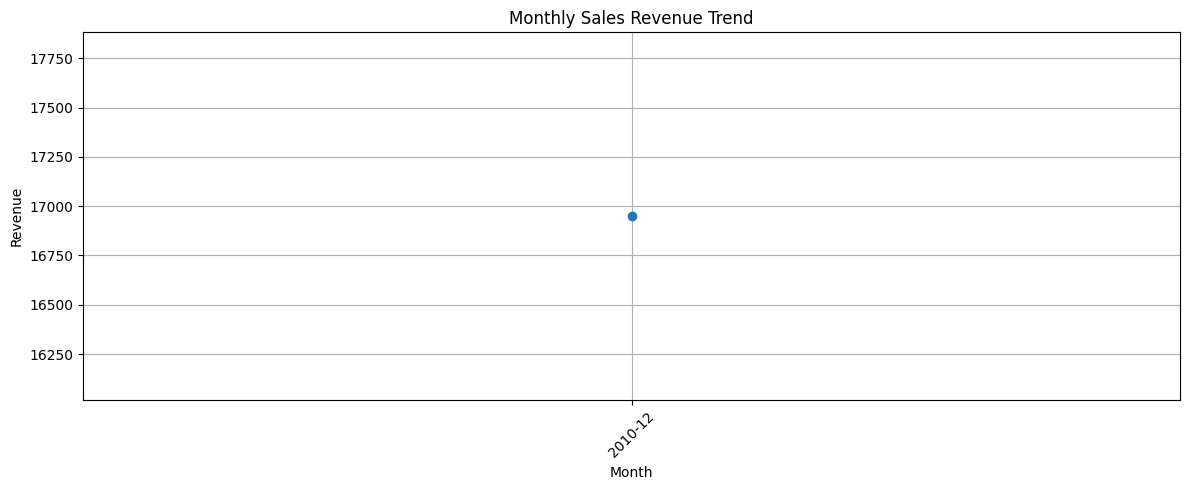

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract month from invoice date
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M").astype(str)

# Calculate monthly revenue
monthly_sales = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
    .sort_values("Month")
)

# Display monthly sales
display(monthly_sales)

# Create chart
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o"
)
plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Quarterly Sales Revenue:


,Quarter,Revenue
0,2010Q4,16949.16


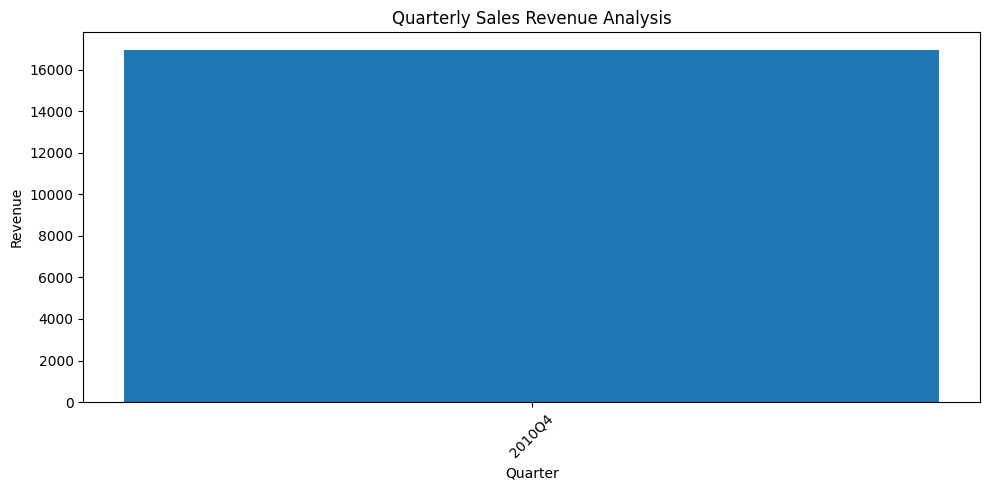

In [8]:
# Extract year and quarter
sales_df["Quarter"] = (
    sales_df["InvoiceDate"].dt.to_period("Q").astype(str)
)

# Calculate quarterly revenue
quarterly_sales = (
    sales_df.groupby("Quarter")["Revenue"]
    .sum()
    .reset_index()
    .sort_values("Quarter")
)

print("Quarterly Sales Revenue:")
display(quarterly_sales)

# Create chart
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(quarterly_sales["Quarter"], quarterly_sales["Revenue"])
plt.title("Quarterly Sales Revenue Analysis")
plt.xlabel("Quarter")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
print("First date:", sales_df["InvoiceDate"].min())
print("Last date:", sales_df["InvoiceDate"].max())

print("\nAvailable quarters:")
print(
    sales_df["InvoiceDate"]
    .dt.to_period("Q")
    .value_counts()
    .sort_index()
)

First date: 2010-12-01 08:26:00
Last date: 2010-12-01 11:45:00

Available quarters:
InvoiceDate
2010Q4    500
Freq: Q-DEC, Name: count, dtype: int64


In [10]:
from google.colab import files
uploaded = files.upload()

Saving online+retail.zip to online+retail.zip


In [11]:
print(uploaded.keys())

dict_keys(['online+retail.zip'])


In [12]:
import zipfile
import os

zip_name = "online+retail.zip"

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/online_retail")

print("ZIP extracted successfully!")
print(os.listdir("/content/online_retail"))

ZIP extracted successfully!
['Online Retail.xlsx']


In [13]:
import os

for root, folders, files_list in os.walk("/content/online_retail"):
    for name in files_list:
        print(os.path.join(root, name))

/content/online_retail/Online Retail.xlsx


In [14]:
import pandas as pd

file_path = "/content/online_retail/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())
print("First 5 rows:")
display(df.head())

Dataset loaded successfully!
Total rows: 541909
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [15]:
sales_df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"], errors="coerce"
)
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Valid sales rows:", len(sales_df))
print("First date:", sales_df["InvoiceDate"].min())
print("Last date:", sales_df["InvoiceDate"].max())

Valid sales rows: 530104
First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:50:00


Quarterly Sales Revenue:


,Quarter,Revenue
0,2010Q4,823746.140
1,2011Q1,1932635.810
2,2011Q2,2070084.541
3,2011Q3,2536949.743
4,2011Q4,3303268.310


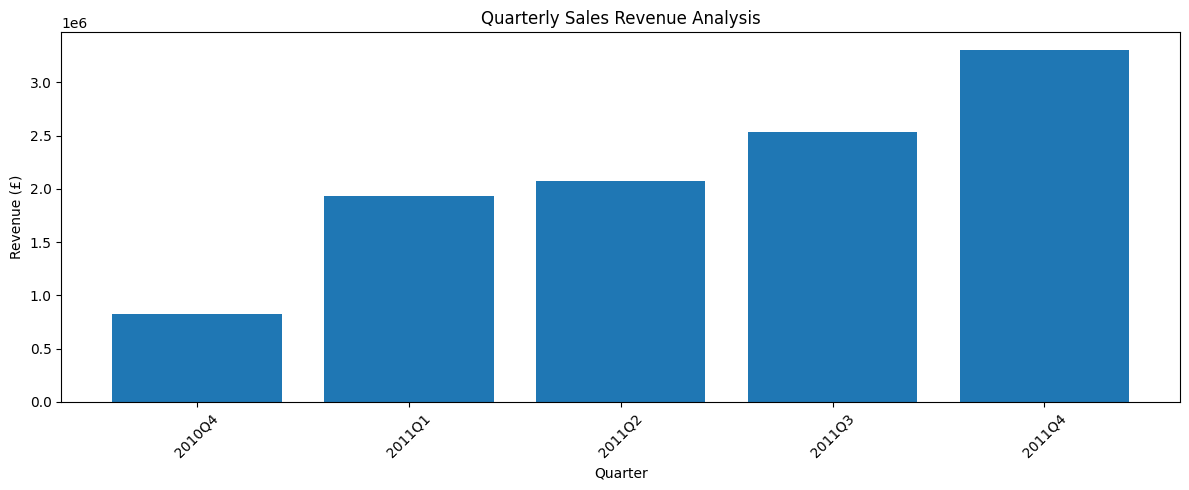

In [16]:
import matplotlib.pyplot as plt

# Extract quarter from invoice date
sales_df["Quarter"] = (
    sales_df["InvoiceDate"].dt.to_period("Q").astype(str)
)

# Calculate revenue for each quarter
quarterly_sales = (
    sales_df.groupby("Quarter")["Revenue"]
    .sum()
    .reset_index()
    .sort_values("Quarter")
)

print("Quarterly Sales Revenue:")
display(quarterly_sales)

# Plot chart
plt.figure(figsize=(12, 5))
plt.bar(quarterly_sales["Quarter"], quarterly_sales["Revenue"])
plt.title("Quarterly Sales Revenue Analysis")
plt.xlabel("Quarter")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Season,Revenue
0,Spring,2025984.001
1,Summer,2240099.471
2,Autumn,3723065.802
3,Winter,2677535.270


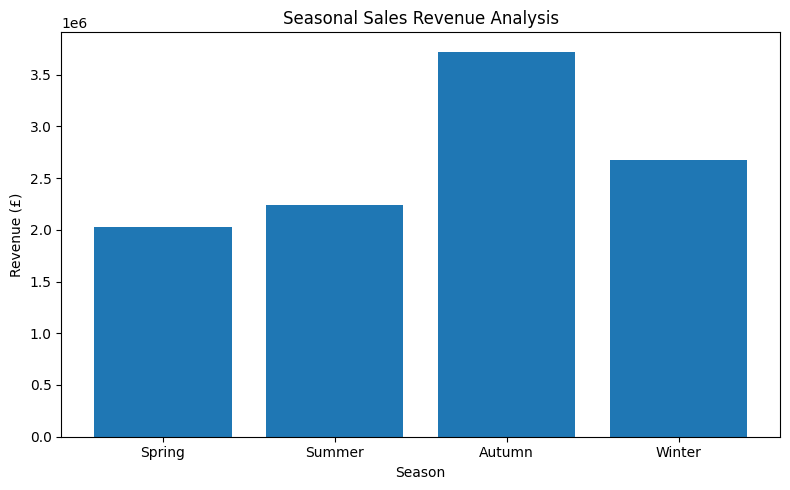

In [17]:
# Extract season from invoice month
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

sales_df["Season"] = sales_df["InvoiceDate"].dt.month.apply(get_season)

seasonal_sales = (
    sales_df.groupby("Season")["Revenue"]
    .sum()
    .reindex(["Spring", "Summer", "Autumn", "Winter"])
    .reset_index()
)

display(seasonal_sales)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(seasonal_sales["Season"], seasonal_sales["Revenue"])
plt.title("Seasonal Sales Revenue Analysis")
plt.xlabel("Season")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

,Description,Total_Revenue,Units_Sold
1067,DOTCOM POSTAGE,206248.77,706
2853,REGENCY CAKESTAND 3 TIER,174484.74,13879
2387,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3844,WHITE HANGING HEART T-LIGHT HOLDER,106292.77,37891
2413,PARTY BUNTING,99504.33,18295
1816,JUMBO BAG RED RETROSPOT,94340.05,48474
2052,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
2192,Manual,78112.82,7225
2692,POSTAGE,78101.88,3150
2741,RABBIT NIGHT LIGHT,66964.99,30788


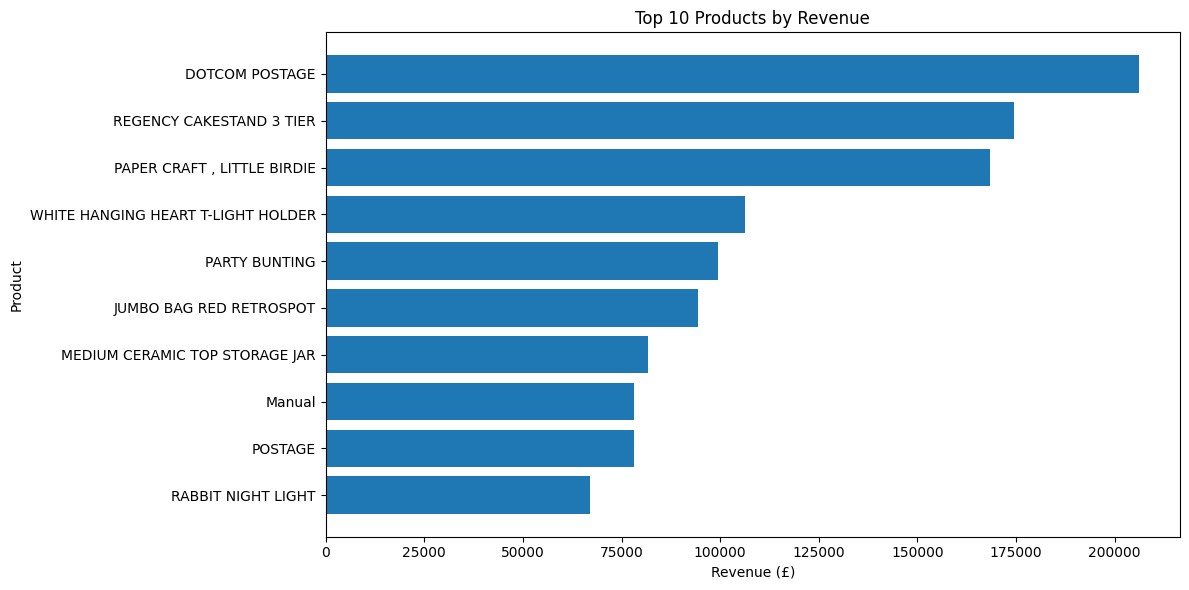

In [19]:
import matplotlib.pyplot as plt

# Find top 10 products by revenue
top_products = (
    sales_df.groupby("Description")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
)

display(top_products)

# Plot top 10 products
plt.figure(figsize=(12, 6))
plt.barh(
    top_products["Description"].astype(str).iloc[::-1],
    top_products["Total_Revenue"].iloc[::-1]
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Top 10 Products by Quantity Sold:


,Description,Quantity
2387,"PAPER CRAFT , LITTLE BIRDIE",80995
2052,MEDIUM CERAMIC TOP STORAGE JAR,78033
3934,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
1816,JUMBO BAG RED RETROSPOT,48474
3844,WHITE HANGING HEART T-LIGHT HOLDER,37891
2681,POPCORN HOLDER,36761
227,ASSORTED COLOUR BIRD ORNAMENT,36461
2337,PACK OF 72 RETROSPOT CAKE CASES,36419
2741,RABBIT NIGHT LIGHT,30788
2107,MINI PAINT SET VINTAGE,26633


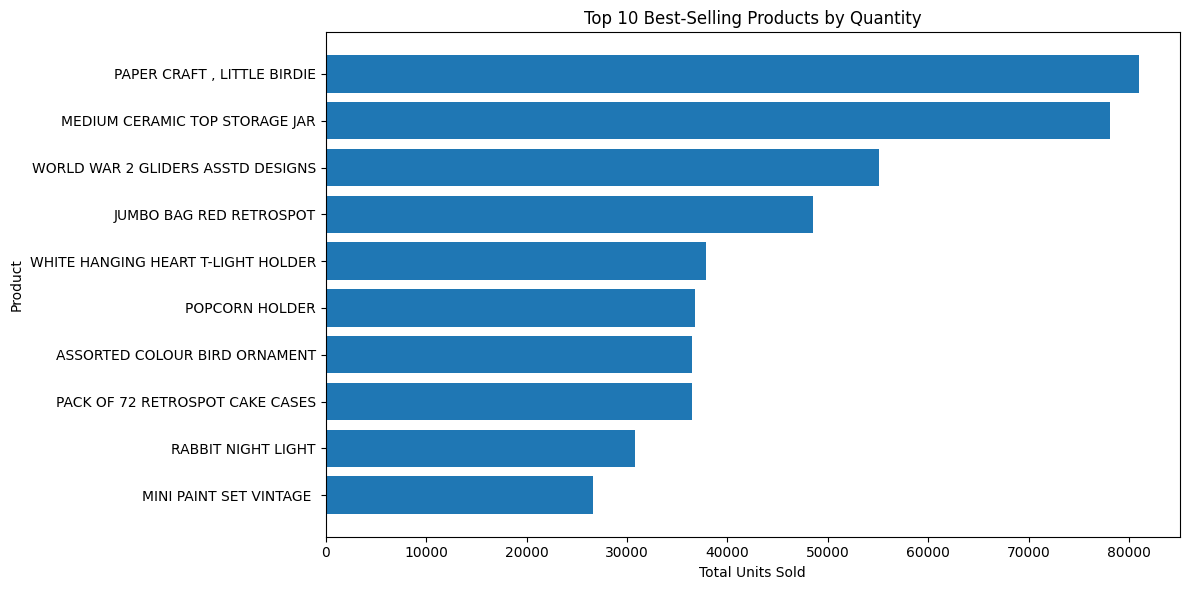

In [20]:
import matplotlib.pyplot as plt

# Find top 10 products by quantity sold
top_quantity = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .reset_index()
    .sort_values("Quantity", ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
display(top_quantity)

# Create chart
plt.figure(figsize=(12, 6))
plt.barh(
    top_quantity["Description"].astype(str).iloc[::-1],
    top_quantity["Quantity"].iloc[::-1]
)
plt.title("Top 10 Best-Selling Products by Quantity")
plt.xlabel("Total Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Top 10 Countries by Sales Revenue:


,Country,Revenue
0,United Kingdom,9025222.084
1,Netherlands,285446.340
2,EIRE,283453.960
3,Germany,228867.140
4,France,209715.110
5,Australia,138521.310
6,Spain,61577.110
7,Switzerland,57089.900
8,Belgium,41196.340
9,Sweden,38378.330


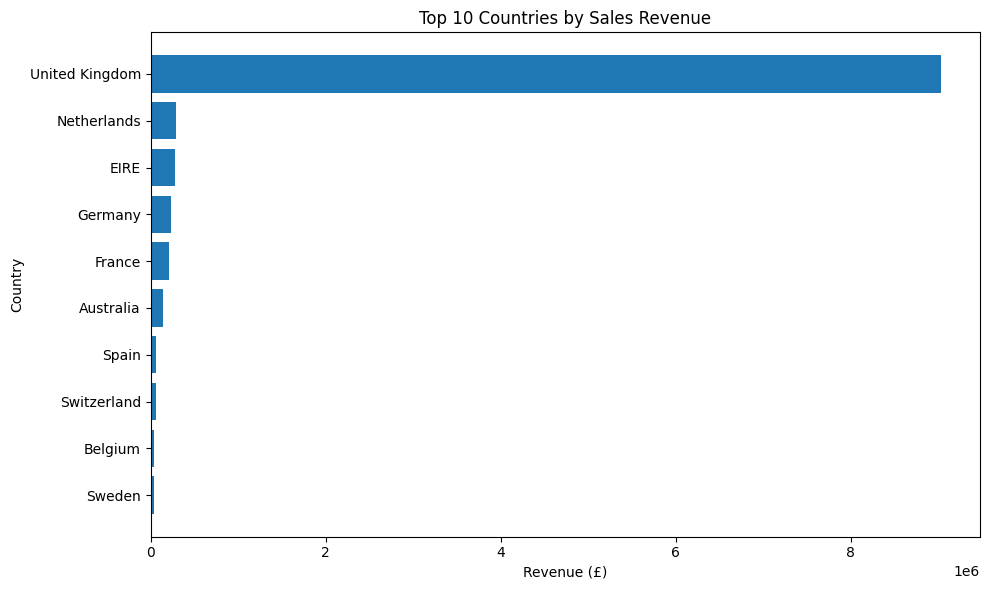

In [21]:
import matplotlib.pyplot as plt

# Calculate revenue by country
country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 Countries by Sales Revenue:")
display(country_sales)

# Create chart
plt.figure(figsize=(10, 6))
plt.barh(
    country_sales["Country"].iloc[::-1],
    country_sales["Revenue"].iloc[::-1]
)
plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [22]:
# Calculate key business metrics
total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_quantity = sales_df["Quantity"].sum()
average_order_value = (
    total_revenue / total_orders if total_orders > 0 else 0
)
unique_products = sales_df["Description"].nunique()
unique_countries = sales_df["Country"].nunique()

print("===== SALES ANALYSIS KPI SUMMARY =====")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")
print(f"Unique Products: {unique_products:,}")
print(f"Countries Served: {unique_countries:,}")

===== SALES ANALYSIS KPI SUMMARY =====
Total Revenue: £10,666,684.54
Total Orders: 19,960
Total Quantity Sold: 5,588,376
Average Order Value: £534.40
Unique Products: 4,026
Countries Served: 38


In [23]:
# Identify the best quarter and country
best_quarter = quarterly_sales.loc[
    quarterly_sales["Revenue"].idxmax()
]

best_country = country_sales.loc[
    country_sales["Revenue"].idxmax()
]

best_product = top_products.loc[
    top_products["Total_Revenue"].idxmax()
]

print("===== BUSINESS INSIGHTS =====")
print(
    f"Highest revenue quarter: {best_quarter['Quarter']} "
    f"(£{best_quarter['Revenue']:,.2f})"
)
print(
    f"Top country by revenue: {best_country['Country']} "
    f"(£{best_country['Revenue']:,.2f})"
)
print(
    f"Top product by revenue: {best_product['Description']} "
    f"(£{best_product['Total_Revenue']:,.2f})"
)

print("\n===== RECOMMENDATIONS =====")
print("1. Plan inventory based on high-revenue periods.")
print("2. Study top-performing products and maintain sufficient stock.")
print("3. Focus marketing on high-revenue countries.")
print("4. Review low-performing periods and products for improvement.")

===== BUSINESS INSIGHTS =====
Highest revenue quarter: 2011Q4 (£3,303,268.31)
Top country by revenue: United Kingdom (£9,025,222.08)
Top product by revenue: DOTCOM POSTAGE (£206,248.77)

===== RECOMMENDATIONS =====
1. Plan inventory based on high-revenue periods.
2. Study top-performing products and maintain sufficient stock.
3. Focus marketing on high-revenue countries.
4. Review low-performing periods and products for improvement.


In [24]:
import os
import matplotlib.pyplot as plt

os.makedirs("Task1_Charts", exist_ok=True)

# Monthly sales chart
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month"], monthly_sales["Revenue"], marker="o")
plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Task1_Charts/monthly_sales.png", dpi=300)
plt.close()

# Quarterly sales chart
plt.figure(figsize=(12, 5))
plt.bar(quarterly_sales["Quarter"], quarterly_sales["Revenue"])
plt.title("Quarterly Sales Revenue")
plt.xlabel("Quarter")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig("Task1_Charts/quarterly_sales.png", dpi=300)
plt.close()

# Top products by revenue
plt.figure(figsize=(12, 6))
plt.barh(
    top_products["Description"].astype(str).iloc[::-1],
    top_products["Total_Revenue"].iloc[::-1]
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("Task1_Charts/top_products_revenue.png", dpi=300)
plt.close()

# Country sales
plt.figure(figsize=(10, 6))
plt.barh(
    country_sales["Country"].iloc[::-1],
    country_sales["Revenue"].iloc[::-1]
)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("Task1_Charts/country_sales.png", dpi=300)
plt.close()

print("All charts saved successfully!")
print(os.listdir("Task1_Charts"))

All charts saved successfully!
['quarterly_sales.png', 'monthly_sales.png', 'top_products_revenue.png', 'country_sales.png']


In [25]:
import shutil
from google.colab import files

shutil.make_archive("Task1_Charts", "zip", "Task1_Charts")
files.download("Task1_Charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
readme_content = """
# Task 1: Sales Data Analysis

## 1. Project Overview
This project analyses the Online Retail dataset to understand sales
performance, revenue trends, popular products, and country-wise sales.

## 2. Objectives
- Calculate total revenue, orders, quantity sold, and Average Order Value.
- Analyse monthly and quarterly revenue trends.
- Identify top-selling products by revenue and quantity.
- Compare sales revenue across countries.
- Provide data-driven business recommendations.

## 3. Dataset
Source: UCI Machine Learning Repository - Online Retail Dataset
https://archive.ics.uci.edu/dataset/352/online+retail

The dataset contains invoice details, product descriptions, quantities,
unit prices, invoice dates, customer IDs, and countries.

## 4. Data Preparation
- Converted invoice dates and numeric columns to appropriate data types.
- Excluded cancelled invoices identified by invoice numbers beginning with C.
- Excluded rows with non-positive quantities or unit prices.
- Calculated revenue as Quantity multiplied by UnitPrice.

## 5. Analysis Performed
- Key performance indicator (KPI) summary
- Monthly revenue trend
- Quarterly revenue trend
- Seasonal revenue analysis
- Top 10 products by revenue
- Top 10 products by quantity sold
- Top 10 countries by revenue

## 6. Business Recommendations
- Plan inventory using historical high-revenue periods.
- Maintain sufficient stock of products generating high revenue.
- Study high-performing markets to guide marketing decisions.
- Investigate low-performing periods and products for improvement.

## 7. Limitations
The dataset does not provide product cost information. Therefore,
actual profit and profit margins cannot be calculated reliably.
Revenue must not be interpreted as profit.

Seasonal patterns should be interpreted cautiously because the dataset
covers a limited historical period.

## 8. Tools Used
- Python
- Pandas
- Matplotlib
- Google Colab

## 9. Output Charts
The Task1_Charts folder contains the exported sales analysis charts.

## 10. Conclusion
The analysis provides an overview of retail sales performance and helps
identify revenue trends, popular products, and important markets.
Business decisions should be based on the calculated results and
the limitations of the available data.
"""

with open("README_Task1.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("README_Task1.md created successfully!")

README_Task1.md created successfully!


In [27]:
from google.colab import files
files.download("README_Task1.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>